# SVR Forecast: USD/EUR

Flow ที่ใช้ใน notebook นี้:

```text
ตรวจและ Clean ข้อมูล
→ กำหนด Target และ Features
→ สร้าง Lag Features
→ แบ่งข้อมูลตามเวลา
→ Scaling เฉพาะ Train
→ Time-Series Cross-validation
→ เลือก Hyperparameters
→ Train โมเดลแต่ละ Split
→ Test กับข้อมูลที่ไม่เคยเห็น
→ เทียบ Naive
→ ตรวจ Diagnostics
→ รายงาน Error %
→ Fit Final Model และ Forecast
```

โจทย์: ใช้ราคา USD/EUR ย้อนหลังเพื่อทำนายราคาวันถัดไปแบบ rolling one-step-ahead โดยไม่ shuffle ข้อมูล


In [1]:
# 1) Environment
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import jarque_bera, ttest_1samp
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import statsmodels.api as sm

warnings.filterwarnings("ignore")

SEED = 42
CV_SPLITS = 3
EPSILON_VALUE = 1e-12

DATA_FILENAME = "USD_EUR Historical Data.csv"
data_candidates = [
    Path.cwd() / "Project_stat" / DATA_FILENAME,
    Path.cwd().parent / "Project_stat" / DATA_FILENAME,
]
DATA_PATH = next(
    (path.resolve() for path in data_candidates if path.exists()),
    None,
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"ไม่พบ {DATA_FILENAME}; ให้รัน notebook จาก root หรือ Python folder ของโปรเจกต์"
    )

print("Data path:", DATA_PATH)


Data path: C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv


## 2) ตรวจและ Clean ข้อมูล

แก้เฉพาะปัญหาที่พบจริง ไม่เติมวันหยุดตลาดและไม่ลบ price spikes อัตโนมัติ ส่วน `Vol.` ไม่ใช้เพราะ missing เป็นสัดส่วนสูง


In [2]:
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="coerce",
)

ohlc_columns = ["Price", "Open", "High", "Low"]
for column in ohlc_columns:
    df[column] = pd.to_numeric(
        df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

df["Change_pct"] = pd.to_numeric(
    df["Change %"].astype(str).str.replace("%", "", regex=False),
    errors="coerce",
) / 100

invalid_dates = int(df["Date"].isna().sum())
duplicate_dates = int(df["Date"].duplicated().sum())
missing_ohlc = int(df[ohlc_columns].isna().any(axis=1).sum())
missing_volume = int(df["Vol."].isna().sum())
nonpositive_rows = int((df[ohlc_columns] <= 0).any(axis=1).sum())

valid_high = df["High"] >= df[["Open", "Price", "Low"]].max(axis=1)
valid_low = df["Low"] <= df[["Open", "Price", "High"]].min(axis=1)
invalid_ohlc_rows = int((~(valid_high & valid_low)).sum())

rows_before = len(df)
df = (
    df.dropna(subset=["Date", *ohlc_columns])
      .loc[lambda x: (x[ohlc_columns] > 0).all(axis=1)]
      .loc[
          lambda x: (
              (x["High"] >= x[["Open", "Price", "Low"]].max(axis=1))
              & (x["Low"] <= x[["Open", "Price", "High"]].min(axis=1))
          )
      ]
      .sort_values("Date")
      .drop_duplicates(subset="Date", keep="last")
      .reset_index(drop=True)
)

# Vol. ไม่ใช้ใน univariate SVR; raw_df ไม่ถูกแก้ไข
df = df.drop(columns=["Vol.", "Change %"])

# Flag return outlier แต่ไม่ลบโดยอัตโนมัติ
df["log_return"] = np.log(df["Price"]).diff()
return_median = df["log_return"].median()
return_mad = (df["log_return"] - return_median).abs().median()

if return_mad > 0:
    df["return_robust_z"] = (
        0.6745 * (df["log_return"] - return_median) / return_mad
    )
else:
    df["return_robust_z"] = 0.0

df["possible_outlier"] = df["return_robust_z"].abs() > 6
possible_outliers = int(df["possible_outlier"].sum())

price = df.set_index("Date")["Price"].astype(float)

cleaning_report = pd.DataFrame({
    "Check": [
        "Raw rows",
        "Invalid dates",
        "Duplicate dates",
        "Rows with missing OHLC",
        "Rows with non-positive OHLC",
        "Rows with invalid OHLC relationship",
        "Missing Vol.",
        "Rows removed during cleaning",
        "Possible return outliers retained",
        "Final usable rows",
    ],
    "Value": [
        len(raw_df),
        invalid_dates,
        duplicate_dates,
        missing_ohlc,
        nonpositive_rows,
        invalid_ohlc_rows,
        missing_volume,
        rows_before - len(df),
        possible_outliers,
        len(price),
    ],
    "Action": [
        "reference",
        "drop if present",
        "keep last if present",
        "drop if present",
        "drop if present",
        "drop if present",
        "exclude Vol. feature",
        "reported",
        "flag only; retain real market moves",
        "model input",
    ],
})

display(cleaning_report)
print("Date range:", price.index.min().date(), "to", price.index.max().date())


,Check,Value,Action
0,Raw rows,1044,reference
1,Invalid dates,0,drop if present
2,Duplicate dates,0,keep last if present
3,Rows with missing OHLC,0,drop if present
4,Rows with non-positive OHLC,0,drop if present
5,Rows with invalid OHLC relationship,0,drop if present
6,Missing Vol.,895,exclude Vol. feature
7,Rows removed during cleaning,0,reported
8,Possible return outliers retained,0,flag only; retain real market moves
9,Final usable rows,1044,model input


Date range: 2022-07-01 to 2026-07-01


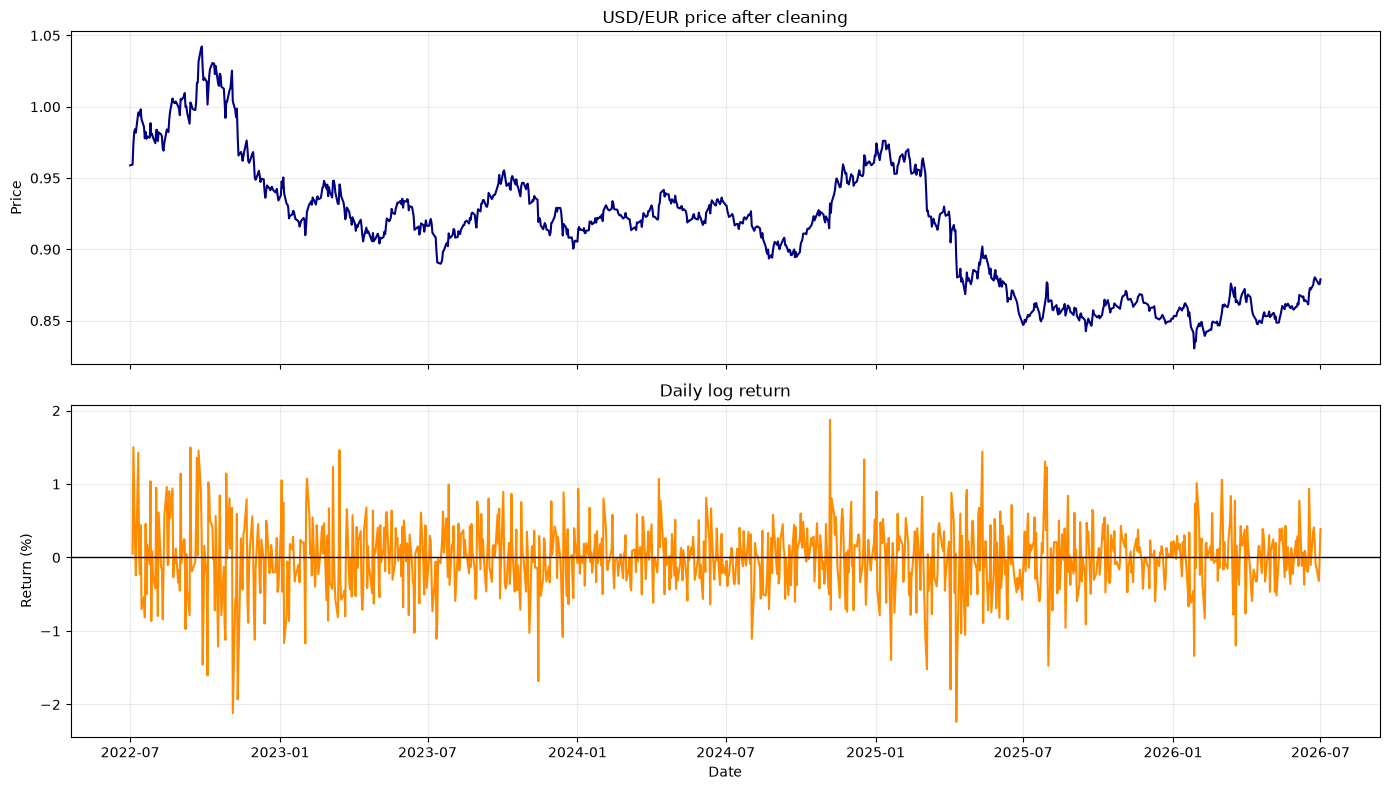

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(price.index, price, color="navy")
axes[0].set_title("USD/EUR price after cleaning")
axes[0].set_ylabel("Price")
axes[0].grid(alpha=0.25)

axes[1].plot(df["Date"], df["log_return"] * 100, color="darkorange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Daily log return")
axes[1].set_ylabel("Return (%)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 3) กำหนด Target, Features และสร้าง Lag Features

- Target: `Price` ของ observation ถัดไป
- Features: ราคาในอดีต `lookback` observations
- SVR รับข้อมูล 2 มิติ ดังนั้นหนึ่งแถวจะเป็น `[lag_lookback, ..., lag_1]`


In [4]:
def make_training_lags(series, lookback):
    values = series.to_numpy(dtype=float)
    X, y, dates = [], [], []

    for target_index in range(lookback, len(values)):
        X.append(values[target_index - lookback:target_index])
        y.append(values[target_index])
        dates.append(series.index[target_index])

    columns = [
        f"Price_lag_{lag}"
        for lag in range(lookback, 0, -1)
    ]
    return (
        pd.DataFrame(X, index=dates, columns=columns),
        pd.Series(y, index=dates, name="Target"),
    )


def make_evaluation_lags(history_series, evaluation_series, lookback):
    # ใช้ค่าจริงล่าสุดที่ทราบเป็น context สำหรับ rolling one-step forecast
    combined = pd.concat([
        history_series.iloc[-lookback:],
        evaluation_series,
    ])
    X, y = make_training_lags(combined, lookback)
    X = X.loc[evaluation_series.index]
    y = y.loc[evaluation_series.index]

    assert len(X) == len(evaluation_series)
    return X, y


example_X, example_y = make_training_lags(price, lookback=5)
print("Example feature shape:", example_X.shape)
display(example_X.head())
display(example_y.head().to_frame())


Example feature shape: (1039, 5)


,Price_lag_5,Price_lag_4,Price_lag_3,Price_lag_2,Price_lag_1
2022-07-08,0.9589,0.9594,0.9739,0.9822,0.9842
2022-07-11,0.9594,0.9739,0.9822,0.9842,0.9818
2022-07-12,0.9739,0.9822,0.9842,0.9818,0.9959
2022-07-13,0.9822,0.9842,0.9818,0.9959,0.9961
2022-07-14,0.9842,0.9818,0.9959,0.9961,0.9938


,Target
2022-07-08,0.9818
2022-07-11,0.9959
2022-07-12,0.9961
2022-07-13,0.9938
2022-07-14,0.9982


## 4) แบ่งข้อมูลตามเวลา

เปรียบเทียบ 80/20 และ 70/15/15 โดยไม่ shuffle และรายงาน test period เพราะสองกลยุทธ์มีช่วงทดสอบต่างกัน


In [5]:
n = len(price)

split_80 = int(n * 0.80)
train_80 = price.iloc[:split_80]
test_20 = price.iloc[split_80:]

train_end_70 = int(n * 0.70)
validation_end_85 = int(n * 0.85)
train_70 = price.iloc[:train_end_70]
validation_15 = price.iloc[train_end_70:validation_end_85]
test_15 = price.iloc[validation_end_85:]

split_report = pd.DataFrame([
    {
        "Strategy": "80/20",
        "Train": len(train_80),
        "Validation": 0,
        "Test": len(test_20),
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
    },
    {
        "Strategy": "70/15/15",
        "Train": len(train_70),
        "Validation": len(validation_15),
        "Test": len(test_15),
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
    },
])

display(split_report)


,Strategy,Train,Validation,Test,Test start,Test end
0,80/20,835,0,209,2025-09-12,2026-07-01
1,70/15/15,730,157,157,2025-11-25,2026-07-01


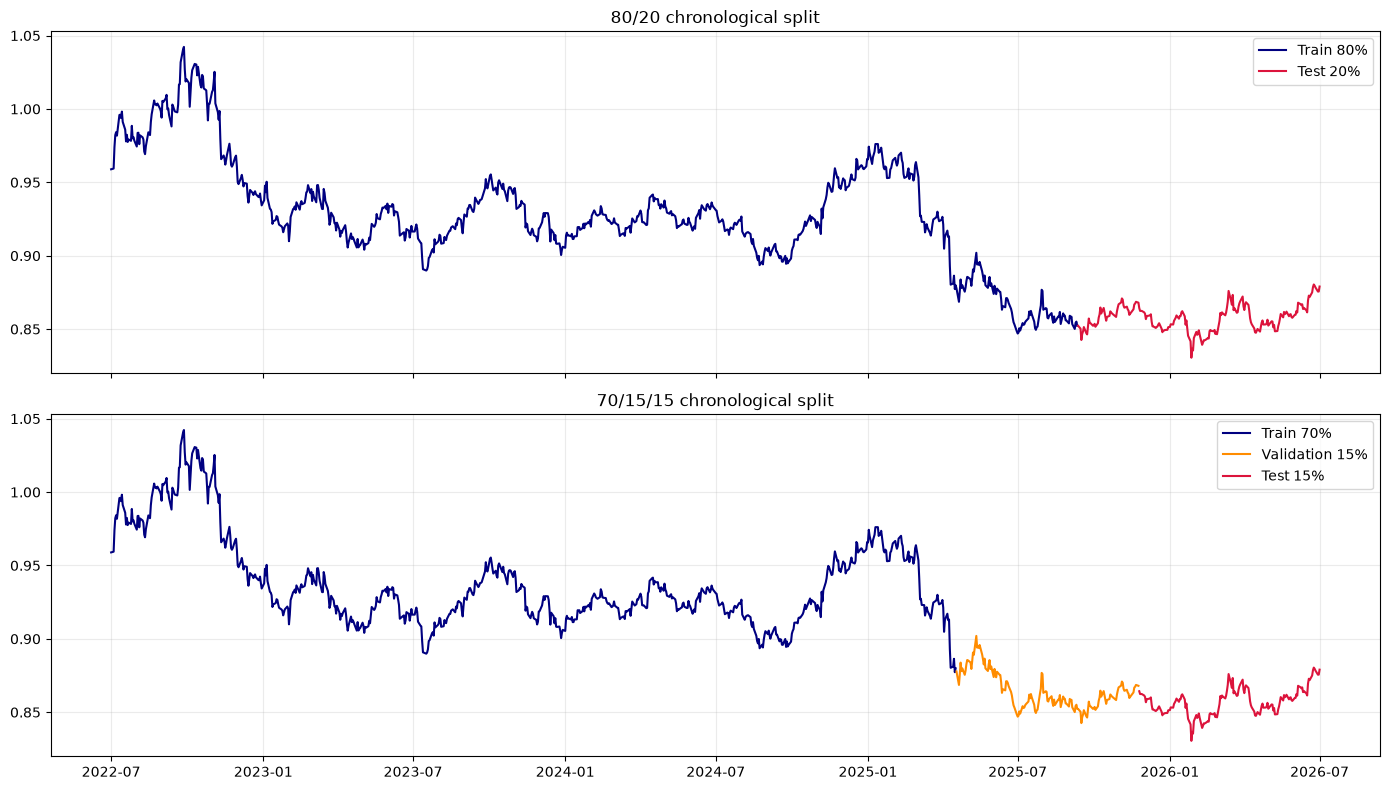

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(train_80.index, train_80, label="Train 80%", color="navy")
axes[0].plot(test_20.index, test_20, label="Test 20%", color="crimson")
axes[0].set_title("80/20 chronological split")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(train_70.index, train_70, label="Train 70%", color="navy")
axes[1].plot(
    validation_15.index,
    validation_15,
    label="Validation 15%",
    color="darkorange",
)
axes[1].plot(test_15.index, test_15, label="Test 15%", color="crimson")
axes[1].set_title("70/15/15 chronological split")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 5) Scaling เฉพาะ Train และ Metrics

แต่ละ CV fold สร้าง `StandardScaler` ของ X และ y ใหม่ โดย fit เฉพาะ fold train แล้วใช้ `transform` กับ validation/test เพื่อป้องกัน leakage


In [7]:
def calculate_metrics(actual, predicted, previous_actual=None):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    error = actual - predicted

    metrics = {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": (
            np.mean(np.abs(error) / np.maximum(np.abs(actual), EPSILON_VALUE))
            * 100
        ),
        "sMAPE (%)": (
            np.mean(
                2 * np.abs(error)
                / np.maximum(np.abs(actual) + np.abs(predicted), EPSILON_VALUE)
            )
            * 100
        ),
    }

    if previous_actual is not None:
        previous_actual = np.asarray(previous_actual, dtype=float).reshape(-1)
        actual_direction = np.sign(actual - previous_actual)
        predicted_direction = np.sign(predicted - previous_actual)
        metrics["Direction accuracy (%)"] = (
            np.mean(actual_direction == predicted_direction) * 100
        )

    return metrics


def naive_one_step_forecast(history_series, evaluation_series):
    return np.concatenate([
        [history_series.iloc[-1]],
        evaluation_series.iloc[:-1].to_numpy(),
    ])


def fit_svr_train_evaluate(
    training_series,
    evaluation_series,
    config,
):
    lookback = config["lookback"]

    X_train, y_train = make_training_lags(training_series, lookback)
    X_evaluation, y_evaluation = make_evaluation_lags(
        training_series,
        evaluation_series,
        lookback,
    )

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train_scaled = x_scaler.fit_transform(X_train)
    y_train_scaled = y_scaler.fit_transform(
        y_train.to_numpy().reshape(-1, 1)
    ).reshape(-1)
    X_evaluation_scaled = x_scaler.transform(X_evaluation)

    model = SVR(
        kernel=config["kernel"],
        C=config["C"],
        epsilon=config["epsilon"],
        gamma=config.get("gamma", "scale"),
    )
    model.fit(X_train_scaled, y_train_scaled)

    train_prediction = y_scaler.inverse_transform(
        model.predict(X_train_scaled).reshape(-1, 1)
    ).reshape(-1)
    evaluation_prediction = y_scaler.inverse_transform(
        model.predict(X_evaluation_scaled).reshape(-1, 1)
    ).reshape(-1)

    train_metrics = calculate_metrics(y_train, train_prediction)
    evaluation_metrics = calculate_metrics(
        y_evaluation,
        evaluation_prediction,
    )

    return {
        "model": model,
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "train_prediction": train_prediction,
        "prediction": evaluation_prediction,
        "actual": y_evaluation.to_numpy(),
        "train_metrics": train_metrics,
        "metrics": evaluation_metrics,
        "support_vectors": int(model.support_.size),
        "support_fraction": model.support_.size / len(X_train),
    }


## 6) Time-Series Cross-validation และ Hyperparameter selection

ใช้ 3-fold expanding window ภายใน training data เท่านั้น โดยทดลอง:

- Lookback: 5, 10, 20, 30
- Kernel: RBF และ Linear
- `C`, `epsilon`, `gamma` หลายระดับ

เลือก configuration จากค่าเฉลี่ย CV RMSE ต่ำที่สุด


In [8]:
SVR_CONFIGS = []

for lookback in [5, 10, 20, 30]:
    for C in [1.0, 10.0, 100.0]:
        for epsilon in [0.01, 0.05]:
            for gamma in ["scale", 0.1]:
                SVR_CONFIGS.append({
                    "lookback": lookback,
                    "kernel": "rbf",
                    "C": C,
                    "epsilon": epsilon,
                    "gamma": gamma,
                })

    for C in [0.1, 1.0, 10.0]:
        for epsilon in [0.01, 0.05]:
            SVR_CONFIGS.append({
                "lookback": lookback,
                "kernel": "linear",
                "C": C,
                "epsilon": epsilon,
                "gamma": "scale",
            })

print("Candidate configurations:", len(SVR_CONFIGS))


def run_svr_time_series_cv(series, strategy_name, n_splits=3):
    splitter = TimeSeriesSplit(n_splits=n_splits)
    rows = []

    for fold, (train_index, validation_index) in enumerate(
        splitter.split(series), start=1
    ):
        fold_train = series.iloc[train_index]
        fold_validation = series.iloc[validation_index]

        for config_id, config in enumerate(SVR_CONFIGS):
            result = fit_svr_train_evaluate(
                fold_train,
                fold_validation,
                config,
            )
            rows.append({
                "Strategy": strategy_name,
                "Fold": fold,
                "Config ID": config_id,
                "Train size": len(fold_train),
                "Validation size": len(fold_validation),
                **config,
                **result["metrics"],
                "Support fraction": result["support_fraction"],
            })

    return pd.DataFrame(rows)


Candidate configurations: 72


In [9]:
print("Running SVR CV for train 80%...")
cv_results_80 = run_svr_time_series_cv(
    train_80,
    "80/20",
    n_splits=CV_SPLITS,
)

print("Running SVR CV for train 70%...")
cv_results_70 = run_svr_time_series_cv(
    train_70,
    "70/15/15",
    n_splits=CV_SPLITS,
)

cv_fold_results = pd.concat(
    [cv_results_80, cv_results_70],
    ignore_index=True,
)

group_columns = [
    "Strategy",
    "Config ID",
    "lookback",
    "kernel",
    "C",
    "epsilon",
    "gamma",
]

cv_summary = (
    cv_fold_results
    .groupby(group_columns, as_index=False, dropna=False)
    .agg(
        folds=("Fold", "nunique"),
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
        mean_MAPE_pct=("MAPE (%)", "mean"),
        std_MAPE_pct=("MAPE (%)", "std"),
        mean_support_fraction=("Support fraction", "mean"),
    )
    .sort_values(["Strategy", "mean_RMSE"])
    .reset_index(drop=True)
)

display(
    cv_summary.groupby("Strategy", group_keys=False)
    .head(10)
    .round(6)
)


Running SVR CV for train 80%...


Running SVR CV for train 70%...


,Strategy,Config ID,lookback,kernel,C,epsilon,gamma,folds,mean_RMSE,std_RMSE,mean_MAPE_pct,std_MAPE_pct,mean_support_fraction
0,70/15/15,16,5,linear,10.0,0.01,scale,3,0.003990,0.000825,0.326982,0.061725,0.941090
1,70/15/15,14,5,linear,1.0,0.01,scale,3,0.003993,0.000824,0.326957,0.061284,0.942957
2,70/15/15,17,5,linear,10.0,0.05,scale,3,0.003996,0.000833,0.326577,0.061922,0.695798
3,70/15/15,15,5,linear,1.0,0.05,scale,3,0.003999,0.000837,0.326909,0.062368,0.687446
4,70/15/15,12,5,linear,0.1,0.01,scale,3,0.004048,0.000848,0.329485,0.061638,0.943623
5,70/15/15,13,5,linear,0.1,0.05,scale,3,0.004064,0.000860,0.330538,0.063762,0.713213
6,70/15/15,33,10,linear,1.0,0.05,scale,3,0.004077,0.000854,0.331552,0.062925,0.676641
7,70/15/15,32,10,linear,1.0,0.01,scale,3,0.004080,0.000871,0.331608,0.064158,0.931501
8,70/15/15,34,10,linear,10.0,0.01,scale,3,0.004088,0.000859,0.332483,0.063124,0.918594
9,70/15/15,35,10,linear,10.0,0.05,scale,3,0.004094,0.000846,0.333468,0.062995,0.688352


In [10]:
def best_config_for_strategy(summary, strategy):
    best_row = (
        summary.loc[summary["Strategy"] == strategy]
        .sort_values("mean_RMSE")
        .iloc[0]
    )
    return {
        "lookback": int(best_row["lookback"]),
        "kernel": str(best_row["kernel"]),
        "C": float(best_row["C"]),
        "epsilon": float(best_row["epsilon"]),
        "gamma": (
            str(best_row["gamma"])
            if isinstance(best_row["gamma"], str)
            else float(best_row["gamma"])
        ),
    }


BEST_CONFIG_80 = best_config_for_strategy(cv_summary, "80/20")
BEST_CONFIG_70 = best_config_for_strategy(cv_summary, "70/15/15")

print("Best CV config — 80/20:", BEST_CONFIG_80)
print("Best CV config — 70/15/15:", BEST_CONFIG_70)


Best CV config — 80/20: {'lookback': 5, 'kernel': 'linear', 'C': 1.0, 'epsilon': 0.05, 'gamma': 'scale'}
Best CV config — 70/15/15: {'lookback': 5, 'kernel': 'linear', 'C': 10.0, 'epsilon': 0.01, 'gamma': 'scale'}


## 7) Train โมเดลแต่ละ Split และ Test กับข้อมูลที่ไม่เคยเห็น

- 80/20: เลือก config จาก CV ใน train 80% แล้ว fit train 80% ก่อน test 20%
- 70/15/15: เลือก config จาก CV ใน train 70%, ตรวจบน validation 15%, จากนั้น refit train+validation 85% ก่อน test 15%


In [11]:
# Internal holdout สำหรับวัด generalization gap ของ 80/20
internal_cut_80 = int(len(train_80) * 0.90)
diagnostic_fit_80 = fit_svr_train_evaluate(
    train_80.iloc[:internal_cut_80],
    train_80.iloc[internal_cut_80:],
    BEST_CONFIG_80,
)

# Validation check ของ 70/15/15 ก่อนแตะ test
validation_result_70 = fit_svr_train_evaluate(
    train_70,
    validation_15,
    BEST_CONFIG_70,
)

# Final test evaluation ของแต่ละ split
result_80 = fit_svr_train_evaluate(
    train_80,
    test_20,
    BEST_CONFIG_80,
)

train_85 = pd.concat([train_70, validation_15])
result_70 = fit_svr_train_evaluate(
    train_85,
    test_15,
    BEST_CONFIG_70,
)

print(
    "70/15/15 validation MAPE:",
    f"{validation_result_70['metrics']['MAPE (%)']:.3f}%",
)


70/15/15 validation MAPE: 0.375%


## 8) เทียบ Naive และรายงาน Error %

Naive baseline กำหนดให้ราคาที่พยากรณ์เท่ากับราคาจริงล่าสุดที่ทราบ โมเดลที่ซับซ้อนควรชนะ baseline นี้บนข้อมูล test


In [12]:
naive_prediction_80 = naive_one_step_forecast(train_80, test_20)
naive_metrics_80 = calculate_metrics(
    test_20.to_numpy(),
    naive_prediction_80,
    previous_actual=naive_prediction_80,
)

naive_prediction_70 = naive_one_step_forecast(train_85, test_15)
naive_metrics_70 = calculate_metrics(
    test_15.to_numpy(),
    naive_prediction_70,
    previous_actual=naive_prediction_70,
)

previous_actual_80 = naive_prediction_80
previous_actual_70 = naive_prediction_70

svr_metrics_80 = calculate_metrics(
    test_20.to_numpy(),
    result_80["prediction"],
    previous_actual=previous_actual_80,
)
svr_metrics_70 = calculate_metrics(
    test_15.to_numpy(),
    result_70["prediction"],
    previous_actual=previous_actual_70,
)

comparison = pd.DataFrame([
    {
        "Strategy": "80/20",
        "Model": "SVR",
        "Config": str(BEST_CONFIG_80),
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
        **svr_metrics_80,
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_80["RMSE"] - svr_metrics_80["RMSE"])
            / naive_metrics_80["RMSE"]
        ),
    },
    {
        "Strategy": "80/20",
        "Model": "Naive",
        "Config": "previous observed price",
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
        **naive_metrics_80,
        "RMSE better than naive (%)": 0.0,
    },
    {
        "Strategy": "70/15/15",
        "Model": "SVR",
        "Config": str(BEST_CONFIG_70),
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
        **svr_metrics_70,
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_70["RMSE"] - svr_metrics_70["RMSE"])
            / naive_metrics_70["RMSE"]
        ),
    },
    {
        "Strategy": "70/15/15",
        "Model": "Naive",
        "Config": "previous observed price",
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
        **naive_metrics_70,
        "RMSE better than naive (%)": 0.0,
    },
])

display(comparison.round(6))

for strategy in ["80/20", "70/15/15"]:
    row = comparison.loc[
        (comparison["Strategy"] == strategy)
        & (comparison["Model"] == "SVR")
    ].iloc[0]
    print(
        f"{strategy} SVR: MAPE={row['MAPE (%)']:.3f}% | "
        f"sMAPE={row['sMAPE (%)']:.3f}% | "
        f"RMSE={row['RMSE']:.6f} | "
        f"RMSE improvement vs naive={row['RMSE better than naive (%)']:.2f}%"
    )


,Strategy,Model,Config,Test start,Test end,MAE,RMSE,MAPE (%),sMAPE (%),Direction accuracy (%),RMSE better than naive (%)
0,80/20,SVR,"{'lookback': 5, 'kernel': 'linear', 'C': 1.0, ...",2025-09-12,2026-07-01,0.002334,0.003101,0.272276,0.272225,49.282297,-0.879177
1,80/20,Naive,previous observed price,2025-09-12,2026-07-01,0.002330,0.003074,0.271738,0.271736,3.827751,0.000000
2,70/15/15,SVR,"{'lookback': 5, 'kernel': 'linear', 'C': 10.0,...",2025-11-25,2026-07-01,0.002371,0.003221,0.276672,0.276544,52.229299,-1.526254
3,70/15/15,Naive,previous observed price,2025-11-25,2026-07-01,0.002355,0.003173,0.274790,0.274767,4.458599,0.000000


80/20 SVR: MAPE=0.272% | sMAPE=0.272% | RMSE=0.003101 | RMSE improvement vs naive=-0.88%
70/15/15 SVR: MAPE=0.277% | sMAPE=0.277% | RMSE=0.003221 | RMSE improvement vs naive=-1.53%


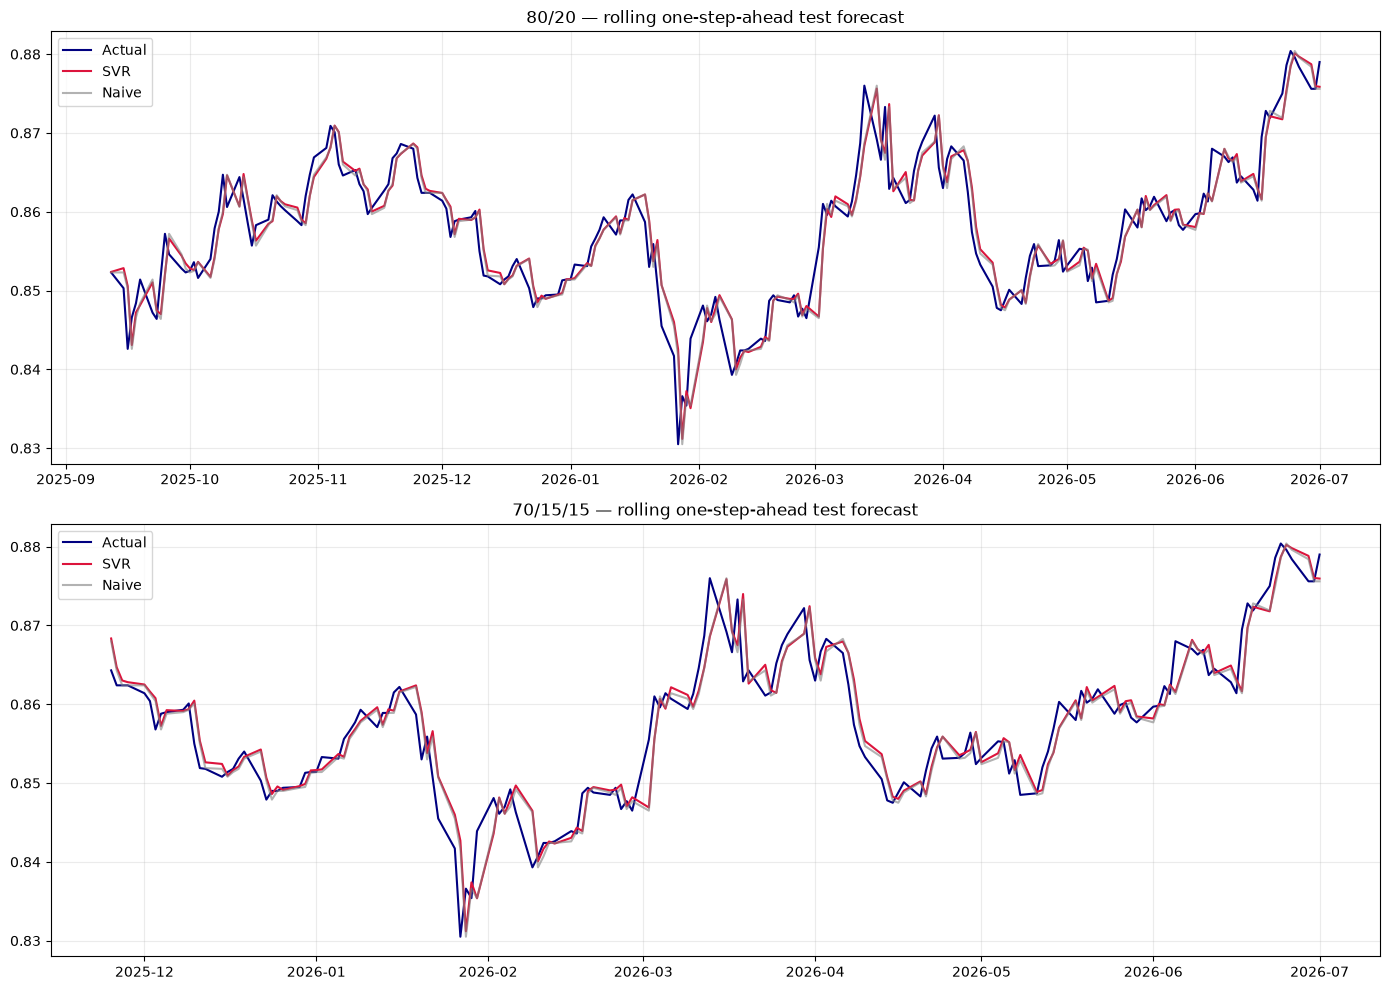

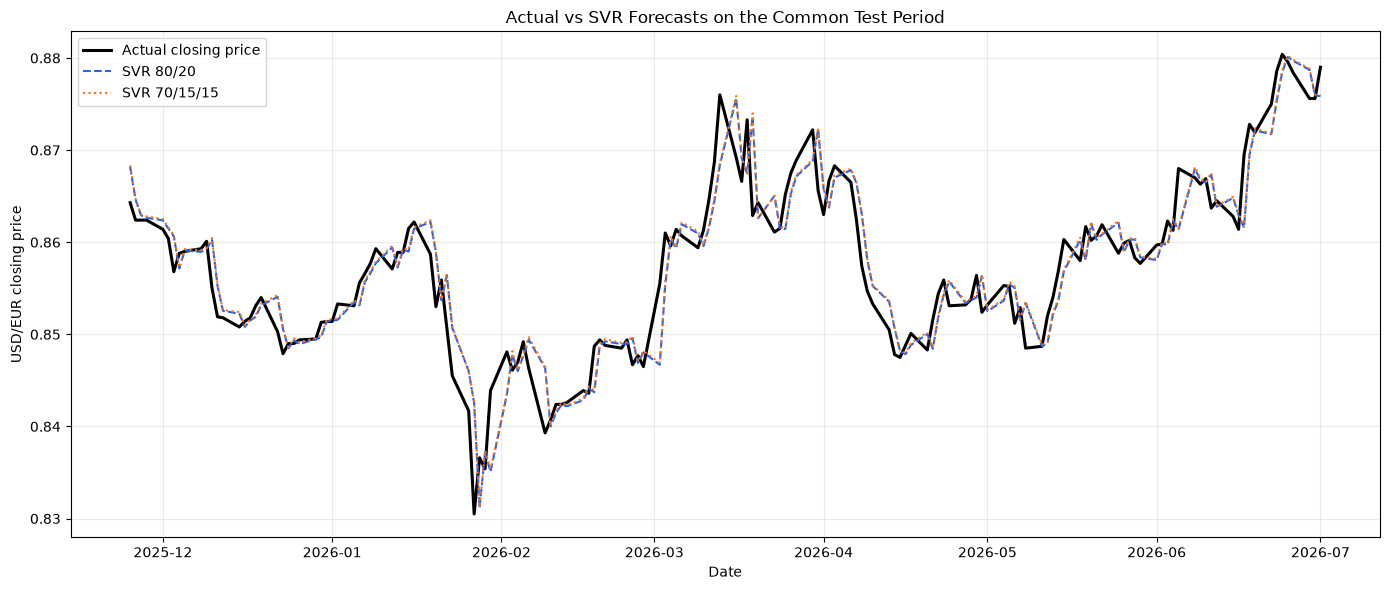

Common test period: 2025-11-25 to 2026-07-01


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(test_20.index, test_20, label="Actual", color="navy")
axes[0].plot(
    test_20.index,
    result_80["prediction"],
    label="SVR",
    color="crimson",
)
axes[0].plot(
    test_20.index,
    naive_prediction_80,
    label="Naive",
    color="grey",
    alpha=0.6,
)
axes[0].set_title("80/20 — rolling one-step-ahead test forecast")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(test_15.index, test_15, label="Actual", color="navy")
axes[1].plot(
    test_15.index,
    result_70["prediction"],
    label="SVR",
    color="crimson",
)
axes[1].plot(
    test_15.index,
    naive_prediction_70,
    label="Naive",
    color="grey",
    alpha=0.6,
)
axes[1].set_title("70/15/15 — rolling one-step-ahead test forecast")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# เปรียบเทียบ forecast ของทั้งสอง split บนช่วง Test ที่มีวันที่ตรงกัน
forecast_80_series = pd.Series(
    result_80["prediction"],
    index=test_20.index,
    name="SVR 80/20",
)
forecast_70_series = pd.Series(
    result_70["prediction"],
    index=test_15.index,
    name="SVR 70/15/15",
)

common_forecast_comparison = pd.concat(
    [
        price.rename("Actual closing price"),
        forecast_80_series,
        forecast_70_series,
    ],
    axis=1,
    join="inner",
).dropna()

plt.figure(figsize=(14, 6))
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["Actual closing price"],
    label="Actual closing price",
    color="black",
    linewidth=2.2,
)
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["SVR 80/20"],
    label="SVR 80/20",
    color="#2563eb",
    linewidth=1.5,
    linestyle="--",
)
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["SVR 70/15/15"],
    label="SVR 70/15/15",
    color="#f97316",
    linewidth=1.5,
    linestyle=":",
)
plt.title("Actual vs SVR Forecasts on the Common Test Period")
plt.xlabel("Date")
plt.ylabel("USD/EUR closing price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Common test period:",
    common_forecast_comparison.index.min().date(),
    "to",
    common_forecast_comparison.index.max().date(),
)


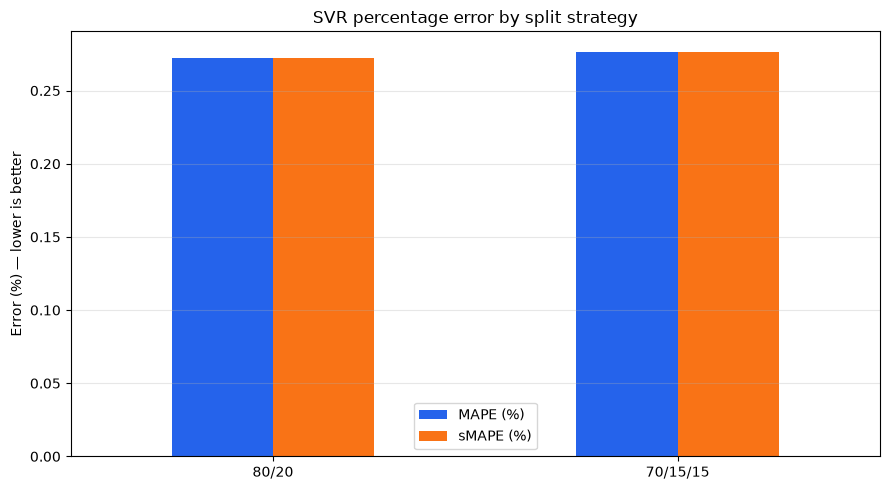

In [14]:
svr_error_plot = (
    comparison.loc[comparison["Model"] == "SVR"]
    .set_index("Strategy")[["MAPE (%)", "sMAPE (%)"]]
)

ax = svr_error_plot.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#2563eb", "#f97316"],
)
ax.set_title("SVR percentage error by split strategy")
ax.set_ylabel("Error (%) — lower is better")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 9) ตรวจ Diagnostics

SVR ไม่ต้องผ่าน stationarity, normality หรือ AR/MA roots แบบ ARIMA แต่ควรตรวจ:

- ไม่มี shuffle และ scaler fit เฉพาะ Train
- Validation/Train RMSE ratio ไม่สูงเกินไป
- Residual ไม่มี mean bias
- Residual ไม่มี autocorrelation
- Normality และ ARCH เป็น diagnostics เพิ่มเติม ไม่ใช่ข้อบังคับของ point forecast


In [15]:
def svr_diagnostics(
    strategy,
    residuals,
    train_rmse,
    validation_rmse,
):
    residuals = np.asarray(residuals, dtype=float).reshape(-1)
    diagnostic_lag = min(10, max(1, len(residuals) // 5))
    generalization_ratio = validation_rmse / max(train_rmse, EPSILON_VALUE)

    _, bias_pvalue = ttest_1samp(residuals, popmean=0.0)
    ljung_pvalue = acorr_ljungbox(
        residuals,
        lags=[diagnostic_lag],
        return_df=True,
    )["lb_pvalue"].iloc[0]
    _, normality_pvalue = jarque_bera(residuals)
    _, arch_pvalue, _, _ = het_arch(
        residuals,
        nlags=diagnostic_lag,
    )

    return pd.DataFrame([
        {
            "Strategy": strategy,
            "Check": "Chronological split / no shuffle",
            "Type": "required",
            "Value": 1.0,
            "Pass rule": "implemented",
            "Pass": True,
        },
        {
            "Strategy": strategy,
            "Check": "X/y scalers fit on training only",
            "Type": "required",
            "Value": 1.0,
            "Pass rule": "implemented",
            "Pass": True,
        },
        {
            "Strategy": strategy,
            "Check": "Generalization: validation/train RMSE ratio",
            "Type": "heuristic",
            "Value": generalization_ratio,
            "Pass rule": "ratio <= 1.50",
            "Pass": generalization_ratio <= 1.50,
        },
        {
            "Strategy": strategy,
            "Check": "Residual mean bias (t-test p-value)",
            "Type": "diagnostic",
            "Value": bias_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": bias_pvalue > 0.05,
        },
        {
            "Strategy": strategy,
            "Check": f"Residual independence (Ljung-Box lag {diagnostic_lag})",
            "Type": "diagnostic",
            "Value": ljung_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": ljung_pvalue > 0.05,
        },
        {
            "Strategy": strategy,
            "Check": "Residual normality (Jarque-Bera p-value)",
            "Type": "optional diagnostic",
            "Value": normality_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": normality_pvalue > 0.05,
        },
        {
            "Strategy": strategy,
            "Check": f"Constant variance (ARCH LM lag {diagnostic_lag})",
            "Type": "optional diagnostic",
            "Value": arch_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": arch_pvalue > 0.05,
        },
    ])


diagnostics = pd.concat([
    svr_diagnostics(
        "80/20",
        test_20.to_numpy() - result_80["prediction"],
        diagnostic_fit_80["train_metrics"]["RMSE"],
        diagnostic_fit_80["metrics"]["RMSE"],
    ),
    svr_diagnostics(
        "70/15/15",
        test_15.to_numpy() - result_70["prediction"],
        validation_result_70["train_metrics"]["RMSE"],
        validation_result_70["metrics"]["RMSE"],
    ),
], ignore_index=True)

diagnostics["Result"] = np.where(diagnostics["Pass"], "PASS", "FAIL")

display(
    diagnostics[
        ["Strategy", "Check", "Type", "Value", "Pass rule", "Result"]
    ].round({"Value": 6})
)

display(
    diagnostics.pivot(
        index="Check",
        columns="Strategy",
        values="Result",
    )
)

complexity_report = pd.DataFrame([
    {
        "Strategy": "80/20",
        "Support vectors": result_80["support_vectors"],
        "Support-vector fraction": result_80["support_fraction"],
    },
    {
        "Strategy": "70/15/15",
        "Support vectors": result_70["support_vectors"],
        "Support-vector fraction": result_70["support_fraction"],
    },
])
display(complexity_report.round(6))


,Strategy,Check,Type,Value,Pass rule,Result
0,80/20,Chronological split / no shuffle,required,1.000000,implemented,PASS
1,80/20,X/y scalers fit on training only,required,1.000000,implemented,PASS
2,80/20,Generalization: validation/train RMSE ratio,heuristic,0.924697,ratio <= 1.50,PASS
3,80/20,Residual mean bias (t-test p-value),diagnostic,0.927205,p > 0.05,PASS
4,80/20,Residual independence (Ljung-Box lag 10),diagnostic,0.012449,p > 0.05,FAIL
5,80/20,Residual normality (Jarque-Bera p-value),optional diagnostic,0.000038,p > 0.05,FAIL
6,80/20,Constant variance (ARCH LM lag 10),optional diagnostic,0.001954,p > 0.05,FAIL
7,70/15/15,Chronological split / no shuffle,required,1.000000,implemented,PASS
8,70/15/15,X/y scalers fit on training only,required,1.000000,implemented,PASS
9,70/15/15,Generalization: validation/train RMSE ratio,heuristic,0.877506,ratio <= 1.50,PASS


Strategy,70/15/15,80/20
Check,,
Chronological split / no shuffle,PASS,PASS
Constant variance (ARCH LM lag 10),FAIL,FAIL
Generalization: validation/train RMSE ratio,PASS,PASS
Residual independence (Ljung-Box lag 10),FAIL,FAIL
Residual mean bias (t-test p-value),PASS,PASS
Residual normality (Jarque-Bera p-value),FAIL,FAIL
X/y scalers fit on training only,PASS,PASS


,Strategy,Support vectors,Support-vector fraction
0,80/20,526,0.633735
1,70/15/15,817,0.926304


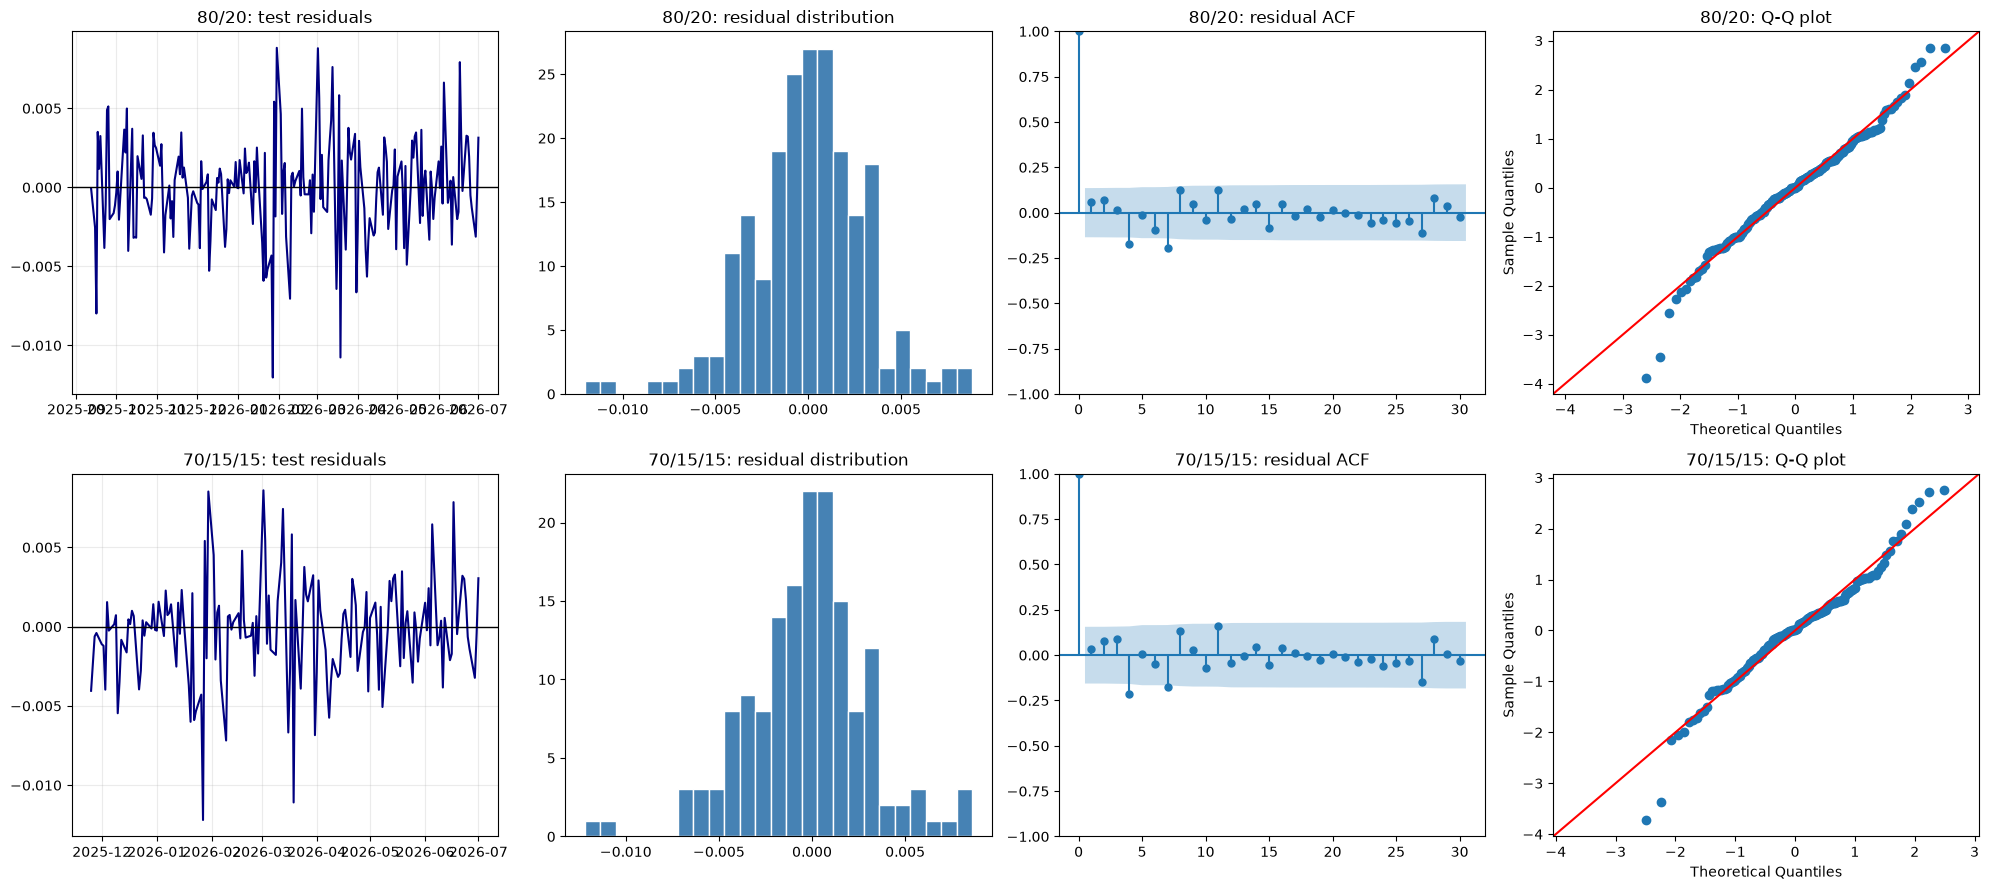

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

residual_plot_data = [
    ("80/20", test_20.index, test_20.to_numpy() - result_80["prediction"]),
    (
        "70/15/15",
        test_15.index,
        test_15.to_numpy() - result_70["prediction"],
    ),
]

for row, (strategy, dates, residuals) in enumerate(residual_plot_data):
    axes[row, 0].plot(dates, residuals, color="navy")
    axes[row, 0].axhline(0, color="black", linewidth=1)
    axes[row, 0].set_title(f"{strategy}: test residuals")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].hist(
        residuals,
        bins=25,
        color="steelblue",
        edgecolor="white",
    )
    axes[row, 1].set_title(f"{strategy}: residual distribution")

    plot_acf(
        residuals,
        lags=min(30, max(1, len(residuals) // 4)),
        ax=axes[row, 2],
    )
    axes[row, 2].set_title(f"{strategy}: residual ACF")

    sm.qqplot(residuals, line="45", fit=True, ax=axes[row, 3])
    axes[row, 3].set_title(f"{strategy}: Q-Q plot")

plt.tight_layout()
plt.show()


## 10) Fit Final Model และ Forecast

สร้าง final SVR ของแต่ละกลยุทธ์ด้วยข้อมูลทั้งหมด และใช้ lag ล่าสุดทำนาย observation ถัดไป ผลนี้ไม่มี confidence interval โดยธรรมชาติแบบ ARIMA


In [17]:
def fit_all_and_forecast_next(full_series, config):
    X, y = make_training_lags(full_series, config["lookback"])

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()
    X_scaled = x_scaler.fit_transform(X)
    y_scaled = y_scaler.fit_transform(
        y.to_numpy().reshape(-1, 1)
    ).reshape(-1)

    model = SVR(
        kernel=config["kernel"],
        C=config["C"],
        epsilon=config["epsilon"],
        gamma=config.get("gamma", "scale"),
    )
    model.fit(X_scaled, y_scaled)

    last_window = full_series.iloc[-config["lookback"]:].to_numpy().reshape(1, -1)
    last_window_scaled = x_scaler.transform(last_window)
    forecast_scaled = model.predict(last_window_scaled).reshape(-1, 1)
    forecast = float(y_scaler.inverse_transform(forecast_scaled)[0, 0])

    return model, x_scaler, y_scaler, forecast


final_model_80, final_x_scaler_80, final_y_scaler_80, forecast_80 = (
    fit_all_and_forecast_next(price, BEST_CONFIG_80)
)
final_model_70, final_x_scaler_70, final_y_scaler_70, forecast_70 = (
    fit_all_and_forecast_next(price, BEST_CONFIG_70)
)

next_date = price.index[-1] + pd.offsets.BDay(1)

next_day_forecasts = pd.DataFrame([
    {
        "Source strategy": "80/20",
        "Forecast date": next_date.date(),
        "Last observed price": price.iloc[-1],
        "SVR forecast": forecast_80,
        "Change from last price (%)": (
            (forecast_80 / price.iloc[-1]) - 1
        ) * 100,
        "Config": str(BEST_CONFIG_80),
    },
    {
        "Source strategy": "70/15/15",
        "Forecast date": next_date.date(),
        "Last observed price": price.iloc[-1],
        "SVR forecast": forecast_70,
        "Change from last price (%)": (
            (forecast_70 / price.iloc[-1]) - 1
        ) * 100,
        "Config": str(BEST_CONFIG_70),
    },
])

display(next_day_forecasts.round(6))
print("หมายเหตุ: Forecast date อิงจากวันสุดท้ายในไฟล์ข้อมูล")


,Source strategy,Forecast date,Last observed price,SVR forecast,Change from last price (%),Config
0,80/20,2026-07-02,0.879,0.879023,0.002664,"{'lookback': 5, 'kernel': 'linear', 'C': 1.0, ..."
1,70/15/15,2026-07-02,0.879,0.879075,0.008576,"{'lookback': 5, 'kernel': 'linear', 'C': 10.0,..."


หมายเหตุ: Forecast date อิงจากวันสุดท้ายในไฟล์ข้อมูล


## 11) เกณฑ์การตัดสินใจ

1. MAPE, sMAPE และ RMSE บน test ยิ่งต่ำยิ่งดี
2. `RMSE better than naive (%)` ควรเป็นค่าบวก
3. CV mean error ควรต่ำและ std ระหว่าง folds ไม่สูง
4. Generalization ratio ไม่ควรสูงผิดปกติ
5. Residual ไม่ควรมี bias หรือ autocorrelation เหลืออยู่
6. ต้องรายงาน test period เพราะ 80/20 และ 70/15/15 ใช้ช่วงทดสอบต่างกัน


In [18]:
# Executive summary จากผลที่รันจริง
svr_rows = comparison.loc[comparison["Model"] == "SVR"].copy()
best_mape_row = svr_rows.sort_values("MAPE (%)").iloc[0]

print("=" * 72)
print("SVR EVALUATION SUMMARY")
print("=" * 72)
print(
    f"Lowest observed test MAPE: {best_mape_row['Strategy']} "
    f"= {best_mape_row['MAPE (%)']:.3f}%"
)

for _, row in svr_rows.iterrows():
    baseline_text = (
        "ดีกว่า naive"
        if row["RMSE better than naive (%)"] > 0
        else "ยังไม่ดีกว่า naive"
    )
    print(
        f"{row['Strategy']}: MAPE={row['MAPE (%)']:.3f}%, "
        f"RMSE={row['RMSE']:.6f}, {baseline_text}"
    )

for strategy in ["80/20", "70/15/15"]:
    failed = diagnostics.loc[
        (diagnostics["Strategy"] == strategy)
        & (~diagnostics["Pass"]),
        "Check",
    ].tolist()
    print(
        f"{strategy} diagnostics ที่ไม่ผ่าน:",
        ", ".join(failed) if failed else "ไม่มี",
    )


SVR EVALUATION SUMMARY
Lowest observed test MAPE: 80/20 = 0.272%
80/20: MAPE=0.272%, RMSE=0.003101, ยังไม่ดีกว่า naive
70/15/15: MAPE=0.277%, RMSE=0.003221, ยังไม่ดีกว่า naive
80/20 diagnostics ที่ไม่ผ่าน: Residual independence (Ljung-Box lag 10), Residual normality (Jarque-Bera p-value), Constant variance (ARCH LM lag 10)
70/15/15 diagnostics ที่ไม่ผ่าน: Residual independence (Ljung-Box lag 10), Residual normality (Jarque-Bera p-value), Constant variance (ARCH LM lag 10)
